In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 4.5)
rng = np.random.default_rng(42)

In [3]:
df = pd.read_csv("marketing_AB.csv")

In [4]:
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed")])
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

In [5]:
df["converted"] = df["converted"].astype(str).str.lower().eq("true").astype(int)


In [6]:
print(df.shape)
df.head()

(588101, 6)


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


In [7]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate user IDs:", df["user_id"].duplicated().sum())
print("\nGroup sizes:")
print(df["test_group"].value_counts())
print(df["test_group"].value_counts(normalize=True).round(3))

Missing values per column:
user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64

Duplicate user IDs: 0

Group sizes:
test_group
ad     564577
psa     23524
Name: count, dtype: int64
test_group
ad     0.96
psa    0.04
Name: proportion, dtype: float64


In [8]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=day_order, ordered=True)
df.describe()

,user_id,converted,total_ads,most_ads_hour
count,5.881010e+05,588101.000000,588101.000000,588101.000000
mean,1.310692e+06,0.025239,24.820876,14.469061
std,2.022260e+05,0.156850,43.715181,4.834634
min,9.000000e+05,0.000000,1.000000,0.000000
25%,1.143190e+06,0.000000,4.000000,11.000000
50%,1.313725e+06,0.000000,13.000000,14.000000
75%,1.484088e+06,0.000000,27.000000,18.000000
max,1.654483e+06,1.000000,2065.000000,23.000000


In [9]:
for col in ["most_ads_day", "most_ads_hour"]:
    table = pd.crosstab(df[col], df["test_group"])
    chi2, p, _, _ = stats.chi2_contingency(table)
    print(f"{col}: chi-square p-value = {p:.3f}  ({'groups look balanced' if p > 0.05 else 'possible imbalance, investigate'})")

most_ads_day: chi-square p-value = 0.000  (possible imbalance, investigate)
most_ads_hour: chi-square p-value = 0.000  (possible imbalance, investigate)


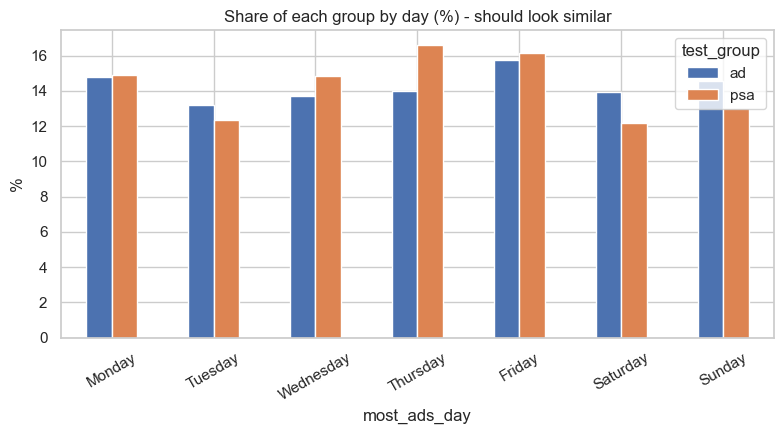

In [10]:
share = pd.crosstab(df["most_ads_day"], df["test_group"], normalize="columns").mul(100)
share.plot(kind="bar")
plt.title("Share of each group by day (%) - should look similar")
plt.ylabel("%")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

             users  conversions      rate  rate_%
test_group                                       
ad          564577        14423  0.025547   2.555
psa          23524          420  0.017854   1.785


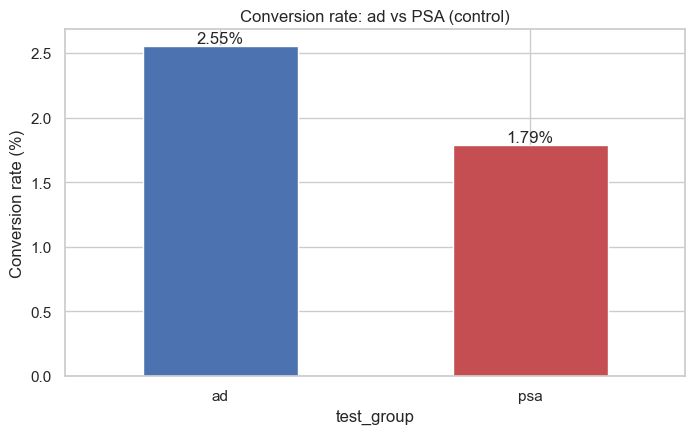

In [11]:
summary = df.groupby("test_group")["converted"].agg(users="count", conversions="sum", rate="mean")
summary["rate_%"] = (summary["rate"] * 100).round(3)
print(summary)

ax = (summary["rate"] * 100).plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate: ad vs PSA (control)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.xticks(rotation=0)
plt.show()

In [12]:
ad = df[df["test_group"] == "ad"]["converted"]
psa = df[df["test_group"] == "psa"]["converted"]
x1, n1 = ad.sum(), len(ad)
x2, n2 = psa.sum(), len(psa)
p1, p2 = x1 / n1, x2 / n2

def two_prop_ztest(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    return z, 2 * (1 - stats.norm.cdf(abs(z)))

z, p_value = two_prop_ztest(x1, n1, x2, n2)
print(f"Ad rate:  {p1:.3%}")
print(f"PSA rate: {p2:.3%}")
print(f"z = {z:.2f}, p-value = {p_value:.2e}")
print("Result:", "statistically significant at 5%" if p_value < 0.05 else "NOT statistically significant")

# Cross-check with chi-square on the 2x2 table
table = pd.crosstab(df["test_group"], df["converted"])
chi2, p_chi, _, _ = stats.chi2_contingency(table, correction=False)
print(f"Chi-square cross-check p-value = {p_chi:.2e}")

Ad rate:  2.555%
PSA rate: 1.785%
z = 7.37, p-value = 1.71e-13
Result: statistically significant at 5%
Chi-square cross-check p-value = 1.71e-13


In [13]:
diff = p1 - p2
se_diff = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
ci_low, ci_high = diff - 1.96*se_diff, diff + 1.96*se_diff
print(f"Absolute lift: {diff*100:.3f} percentage points  (95% CI {ci_low*100:.3f} to {ci_high*100:.3f})")

# Relative lift with bootstrap CI
boot = []
for _ in range(10000):
    b1 = rng.binomial(n1, p1) / n1
    b2 = rng.binomial(n2, p2) / n2
    boot.append((b1 - b2) / b2)
rel_low, rel_high = np.percentile(boot, [2.5, 97.5])
print(f"Relative lift: {(p1-p2)/p2:.1%}  (95% bootstrap CI {rel_low:.1%} to {rel_high:.1%})")

Absolute lift: 0.769 percentage points  (95% CI 0.595 to 0.943)
Relative lift: 43.1%  (95% bootstrap CI 30.5% to 57.6%)


In [14]:
diff = p1 - p2
se_diff = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
ci_low, ci_high = diff - 1.96*se_diff, diff + 1.96*se_diff
print(f"Absolute lift: {diff*100:.3f} percentage points  (95% CI {ci_low*100:.3f} to {ci_high*100:.3f})")

# Relative lift with bootstrap CI
boot = []
for _ in range(10000):
    b1 = rng.binomial(n1, p1) / n1
    b2 = rng.binomial(n2, p2) / n2
    boot.append((b1 - b2) / b2)
rel_low, rel_high = np.percentile(boot, [2.5, 97.5])
print(f"Relative lift: {(p1-p2)/p2:.1%}  (95% bootstrap CI {rel_low:.1%} to {rel_high:.1%})")

Absolute lift: 0.769 percentage points  (95% CI 0.595 to 0.943)
Relative lift: 43.1%  (95% bootstrap CI 30.2% to 57.8%)


In [15]:
diff = p1 - p2
se_diff = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
ci_low, ci_high = diff - 1.96*se_diff, diff + 1.96*se_diff
print(f"Absolute lift: {diff*100:.3f} percentage points  (95% CI {ci_low*100:.3f} to {ci_high*100:.3f})")

# Relative lift with bootstrap CI
boot = []
for _ in range(10000):
    b1 = rng.binomial(n1, p1) / n1
    b2 = rng.binomial(n2, p2) / n2
    boot.append((b1 - b2) / b2)
rel_low, rel_high = np.percentile(boot, [2.5, 97.5])
print(f"Relative lift: {(p1-p2)/p2:.1%}  (95% bootstrap CI {rel_low:.1%} to {rel_high:.1%})")

Absolute lift: 0.769 percentage points  (95% CI 0.595 to 0.943)
Relative lift: 43.1%  (95% bootstrap CI 30.7% to 58.5%)


             users      rate  rate_%
ads_bucket                          
1-5         169962  0.002512    0.25
6-10         79537  0.004853    0.49
11-20       123334  0.008400    0.84
21-50       125541  0.029154    2.92
51-100       44149  0.116311   11.63
100+         22054  0.171352   17.14


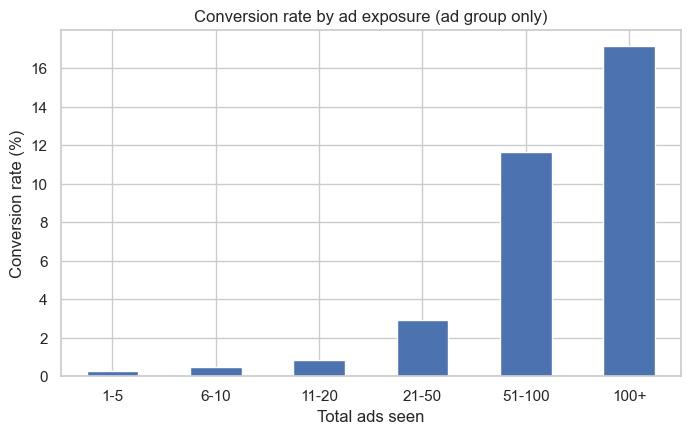

In [16]:
ad_df = df[df["test_group"] == "ad"].copy()
bins = [0, 5, 10, 20, 50, 100, np.inf]
labels = ["1-5", "6-10", "11-20", "21-50", "51-100", "100+"]
ad_df["ads_bucket"] = pd.cut(ad_df["total_ads"], bins=bins, labels=labels)

exposure = ad_df.groupby("ads_bucket", observed=True)["converted"].agg(users="count", rate="mean")
exposure["rate_%"] = (exposure["rate"] * 100).round(2)
print(exposure)

ax = exposure["rate_%"].plot(kind="bar", color="#4C72B0")
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("Total ads seen")
ax.set_title("Conversion rate by ad exposure (ad group only)")
plt.xticks(rotation=0)
plt.show()

In [17]:
alpha_adj = 0.05 / 7
rows = []
for day in day_order:
    sub = df[df["most_ads_day"] == day]
    a, c = sub[sub["test_group"] == "ad"]["converted"], sub[sub["test_group"] == "psa"]["converted"]
    z_d, p_d = two_prop_ztest(a.sum(), len(a), c.sum(), len(c))
    rows.append([day, a.mean()*100, c.mean()*100, (a.mean()-c.mean())*100, p_d, p_d < alpha_adj])
by_day = pd.DataFrame(rows, columns=["Day", "Ad %", "PSA %", "Lift (pts)", "p-value", "Significant after Bonferroni"]).round(3)
by_day

,Day,Ad %,PSA %,Lift (pts),p-value,Significant after Bonferroni
0,Monday,3.324,2.256,1.068,0.001,True
1,Tuesday,3.044,1.445,1.599,0.000,True
2,Wednesday,2.536,1.576,0.960,0.000,True
3,Thursday,2.164,2.023,0.141,0.555,False
4,Friday,2.246,1.630,0.616,0.012,False
5,Saturday,2.131,1.400,0.731,0.007,False
6,Sunday,2.462,2.059,0.402,0.157,False


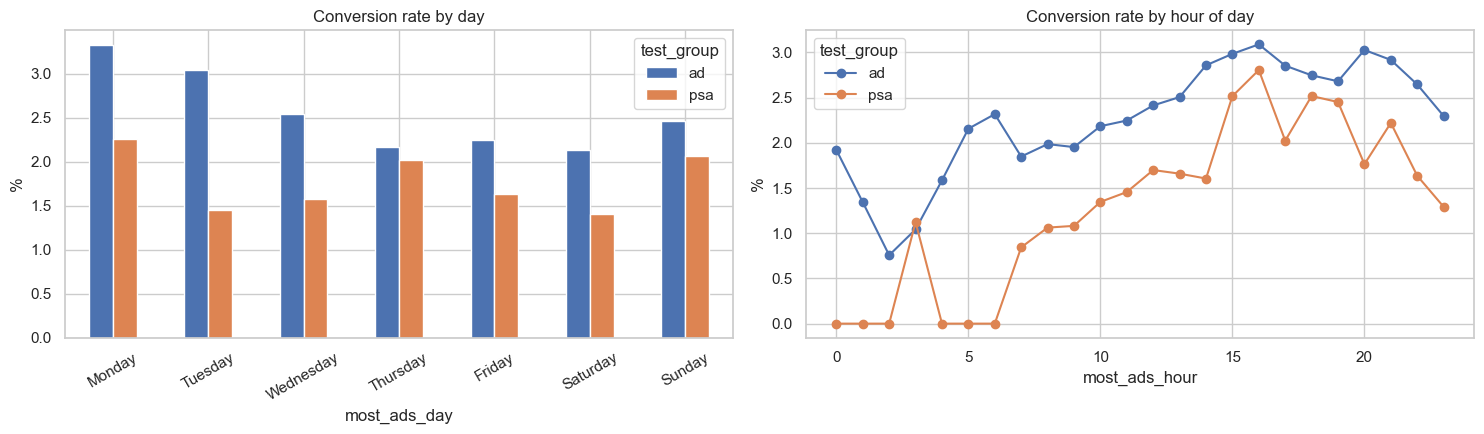

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

by_day_plot = df.groupby(["most_ads_day", "test_group"], observed=True)["converted"].mean().mul(100).unstack()
by_day_plot.plot(kind="bar", ax=axes[0])
axes[0].set_title("Conversion rate by day")
axes[0].set_ylabel("%")
axes[0].tick_params(axis="x", rotation=30)

by_hour = df.groupby(["most_ads_hour", "test_group"])["converted"].mean().mul(100).unstack()
by_hour.plot(ax=axes[1], marker="o")
axes[1].set_title("Conversion rate by hour of day")
axes[1].set_ylabel("%")

plt.tight_layout()
plt.show()

In [19]:
hour_stats = ad_df.groupby("most_ads_hour")["converted"].agg(users="count", rate="mean")
hour_stats = hour_stats[hour_stats["users"] >= 1000]
hour_stats["rate_%"] = (hour_stats["rate"] * 100).round(2)
print("Top 5 hours:\n", hour_stats.sort_values("rate", ascending=False).head(5)[["users", "rate_%"]])
print("\nBottom 5 hours:\n", hour_stats.sort_values("rate").head(5)[["users", "rate_%"]])

Top 5 hours:
                users  rate_%
most_ads_hour               
16             35963    3.09
20             27846    3.03
15             42855    2.98
21             28895    2.92
14             43779    2.86

Bottom 5 hours:
                users  rate_%
most_ads_hour               
2               5152    0.76
3               2590    1.04
1               4615    1.34
7               6168    1.85
0               5309    1.92


In [20]:
cost_per_user_shown_ad = 0.05     # cost to deliver the ad to one user (currency units)
revenue_per_conversion = 25.0     # average revenue from one converted user
# ----------------------------------------------------------

incremental_rate = p1 - p2
incremental_conversions = incremental_rate * n1
incremental_revenue = incremental_conversions * revenue_per_conversion
ad_cost = n1 * cost_per_user_shown_ad
profit = incremental_revenue - ad_cost

print(f"Incremental conversions caused by the ad: {incremental_conversions:,.0f}")
print(f"Incremental revenue: {incremental_revenue:,.0f}")
print(f"Ad cost: {ad_cost:,.0f}")
print(f"Net profit: {profit:,.0f}")
print(f"ROI: {profit/ad_cost:.0%}")

# Break-even: how much must one conversion be worth for the campaign to pay for itself?
breakeven_value = ad_cost / incremental_conversions
print(f"Break-even revenue per conversion: {breakeven_value:,.2f}")

Incremental conversions caused by the ad: 4,343
Incremental revenue: 108,575
Ad cost: 28,229
Net profit: 80,346
ROI: 285%
Break-even revenue per conversion: 6.50


In [ ]:
1. The ad group converted at [X]% versus [Y]% for the PSA control group, an absolute lift of [Z] percentage points (95% CI [low] to [high]) and a relative lift of [R]%.
2. The result is [statistically significant / not significant]** (z = [..], p = [..]).
3. Power check:the test achieved [..]% power, so it was [adequately / inadequately] sized.
4. Exposure:conversion rose with ad exposure, from [X]% (1-5 ads) to [Y]% (100+ ads), though this is correlational.
5. Timing:the ad performed best on [day] and around [hour], but only [these / none] of the day-level differences survived the Bonferroni adjustment.
6. Business impact:under the stated assumptions, the campaign produced about [N] incremental conversions and an ROI of [..]%.